# Loading pre-trained models with xnn's model hub

The `xnn.common.models.hub` module is the model-side twin of the dataset hub. It
has a **one-liner, `from_pretrained()`** function that loads any pre-trained xnn
interatomic potential, regardless of its source origin, under one API:

```python
from xnn.common.models import from_pretrained, list_models

# MACE foundation model
model = from_pretrained("mace-off23-small")

# One head of a multi-head model
model = from_pretrained("mace-mh-0", head="omat_pbe")

# A model trained with xnn
model = from_pretrained("xnn-mace-argon")

# A model published on Zenodo
model = from_pretrained("doi:10.5281/zenodo.18957344",
                        filename="mace_csfapbbri_al_5_1_stagetwo.model")

# A local trainer checkpoint
model = from_pretrained("runs/exp/best.pt")
```

The first call downloads the model artifacts (MD5-verified) into a cache
directory of your choice (using `cache_dir=`), converts external formats such as
`mace-torch` **once**, and stores the result as an xnn **portable model
directory** which consists of a `card.json`, a `config.yaml`, and a `model.pt`,
with no pickled Python objects and no absolute paths. Later calls to
``from_pretrained`` will load that directory offline, without the upstream
package, and the directory can be copied to another machine and used there as
is.

This notebook walks you through:

1. Discovering the available models (`list_models()`, and model cards)
2. The one-liner ``from_pretrained()`` and what will be stored in the cache
3. Using a foundation model for making predictions on molecules drawn from the
   S22 water dimer dataset
4. A materials foundation model and the silicon equation of state
5. Multi-head models: One head per level of theory
6. A model trained with `xnn` on the liquid argon dataset
7. Models published on Zenodo
8. Portability: copying a cached directory to another machine
9. Sharing your own models (the `save_pretrained()` API, `xnn models pack` CLI, the model registry)
10. The same names are used in every xnn interface: ASE, MDI, `MACE.from_foundation()`, the
    CLI

## 0. Setup

All files and artifacts this notebook downloads or converts go into
`runs/model_cache/` next to it (controlled by setting `cache_dir=`). The
`xnn-mace-argon` model of section 6 is read from a default cache directory.
Logged warnings are shown so that the license notices of ASL-licensed models
appear explicitly. The TorchScript warnings e3nn emits while building its
modules, and the import banner of `mace-torch`, are all silenced.

In [1]:
import json
import logging
import shutil
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore", category=FutureWarning)
# e3nn's compiled tensor products warn once per module built (harmless)
warnings.filterwarnings("ignore", message="The TorchScript type system")
warnings.filterwarnings("ignore", category=UserWarning, module="torch.jit")
# mace-torch (needed only to convert upstream checkpoints) prints a banner on import
import contextlib, io

with contextlib.redirect_stdout(io.StringIO()):
    try:
        import mace.modules  # noqa: F401
    except ImportError:
        pass
logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
pd.set_option("display.max_colwidth", 70)

from xnn.common.models import (
    from_pretrained,
    list_models,
    load_pretrained,
    model_card,
    register_pretrained,
    save_pretrained,
)
from xnn.common.models.hub import default_model_cache_dir, fetch_model

CACHE = Path("runs/model_cache")
shutil.rmtree(CACHE, ignore_errors=True)
print("notebook cache:", CACHE.resolve())
print("default cache: ", default_model_cache_dir())

# Helper function to print a directory tree with file sizes
def tree(root, max_depth=3):
    root = Path(root)
    for p in sorted(root.rglob("*")):
        depth = len(p.relative_to(root).parts)
        if depth > max_depth:
            continue
        size = f"  ({p.stat().st_size / 1e6:.2f} MB)" if p.is_file() else "/"
        print("    " * (depth - 1) + p.name + size)

notebook cache: /D3/sina/xnns/notebooks/examples/common/models/runs/model_cache
default cache:  /D3/sina/xnns/models


## 1. What models are available?

The `list_models()` lists the available models in xnn's model **registry**
(tracked by the `models.json` file shipped inside the package, plus anything
added with `register_pretrained`) together with every model directory found in
the cache. With `details=True`, the `list_models()` function returns one row per
model, in which the `cached` column says what is on disk already. Possible
cached states are `ready` (loads offline), `raw` (the upstream file is on disk
and is converted on first load. Here, the files `mace-torch` keeps in
`~/.cache/mace` are reused), an empty cell (needs a download), or `unsupported`.

In [2]:
# List the available models in xnn's model registry
rows = pd.DataFrame(list_models(details=True)).set_index("name")
rows

,architecture,format,cutoff,elements,heads,license,cached,description
name,,,,,,,,
aimnet2-b973c-2025-d3-0,aimnet2,aimnet2,5.0,14,,MIT,,AIMNet2-2025 B97-3c model with improved intermolecular interaction...
aimnet2-b973c-2025-d3-1,aimnet2,aimnet2,5.0,14,,MIT,,AIMNet2-2025 B97-3c model with improved intermolecular interaction...
aimnet2-b973c-2025-d3-2,aimnet2,aimnet2,5.0,14,,MIT,,AIMNet2-2025 B97-3c model with improved intermolecular interaction...
aimnet2-b973c-2025-d3-3,aimnet2,aimnet2,5.0,14,,MIT,,AIMNet2-2025 B97-3c model with improved intermolecular interaction...
aimnet2-b973c-d3-0,aimnet2,aimnet2,5.0,14,,MIT,,AIMNet2 B97-3c general organic model (the first-generation trainin...
aimnet2-b973c-d3-1,aimnet2,aimnet2,5.0,14,,MIT,,AIMNet2 B97-3c general organic model (the first-generation trainin...
aimnet2-b973c-d3-2,aimnet2,aimnet2,5.0,14,,MIT,,AIMNet2 B97-3c general organic model (the first-generation trainin...
aimnet2-b973c-d3-3,aimnet2,aimnet2,5.0,14,,MIT,,AIMNet2 B97-3c general organic model (the first-generation trainin...
aimnet2-nse-0,aimnet2,aimnet2,5.0,14,,MIT,,AIMNet2-NSE wB97M-D3 open-shell model: two charge channels equilib...


Filters can narrow the list by format, architecture or tag. The `model_card()`
returns the full card for each model detailing where the model comes from, its
license and citation, cutoff, elements, heads and dtype.

In [3]:
# Filters can narrow the list by format, architecture or tag
print("organic: ", list_models(tag="organic"))
print("xnn:     ", list_models(format="xnn"))
print("in cache:", list_models(CACHE, cached_only=True)[:3], "...")

# The `model_card()` returns the full card for each model with additional
# details
card = model_card("mace-off23-small").to_dict()
card["species"] = f"{len(card['species'])} elements: {card['species']}"
print(json.dumps(card, indent=2))

organic:  ['aimnet2-b973c-2025-d3-0', 'aimnet2-b973c-2025-d3-1', 'aimnet2-b973c-2025-d3-2', 'aimnet2-b973c-2025-d3-3', 'aimnet2-b973c-d3-0', 'aimnet2-b973c-d3-1', 'aimnet2-b973c-d3-2', 'aimnet2-b973c-d3-3', 'aimnet2-nse-0', 'aimnet2-nse-1', 'aimnet2-nse-2', 'aimnet2-nse-3', 'aimnet2-pd-0', 'aimnet2-pd-1', 'aimnet2-pd-2', 'aimnet2-pd-3', 'aimnet2-rxn-0', 'aimnet2-rxn-1', 'aimnet2-rxn-2', 'aimnet2-rxn-3', 'aimnet2-wb97m-d3-0', 'aimnet2-wb97m-d3-1', 'aimnet2-wb97m-d3-2', 'aimnet2-wb97m-d3-3', 'mace-off23-large', 'mace-off23-medium', 'mace-off23-small']
xnn:      ['xnn-mace-argon']
in cache: ['mace-matpes-pbe-0-medium', 'mace-matpes-r2scan-0-medium', 'mace-mh-0'] ...
{
  "name": "mace-off23-small",
  "description": "MACE-OFF23 small: organic molecules (H C N O F P S Cl Br I), trained on SPICE at wB97M-D3(BJ)",
  "format": "mace-torch",
  "architecture": "mace",
  "cutoff": 4.5,
  "species": "10 elements: [1, 6, 7, 8, 9, 15, 16, 17, 35, 53]",
  "dtype": "float64",
  "units": {
    "energy":

## 2. The one-liner model hub function

The `from_pretrained(name)` returns the model wrapped in `ForceStressOutput`
(energies plus autograd forces, and stress with `compute_stress=True`), in eval
mode and in the checkpoint's own dtype. `wrap=False` returns the bare potential.

The first call below finds the upstream `MACE-OFF23_small.model` (in
`mace-torch`'s cache, or downloads it), converts it weight for weight into the
xnn `MACE`, and writes the converted model to the cache.

In [4]:
t0 = time.perf_counter()

# The first call below finds the upstream `MACE-OFF23_small.model` (in
# `mace-torch`'s cache, or downloads it), converts it weight for weight into the
# xnn format, and saves it in the notebook cache.
model = from_pretrained("mace-off23-small", cache_dir=CACHE)

t_first = time.perf_counter() - t0

# Print the model info
print(
    f"{type(model).__name__}({type(model.model).__name__}) | cutoff {model.cutoff} A | "
    f"{next(model.parameters()).dtype} | {sum(p.numel() for p in model.parameters()):,} "
    f"parameters | first load {t_first:.1f} s"
)

WARNING xnn.common.models.hub.loader: mace-off23-small is distributed under the Academic Software License (https://github.com/gabor1/ASL); by using it you accept its terms (no commercial use).


ForceStressOutput(MACE) | cutoff 4.5 A | torch.float64 | 694,520 parameters | first load 4.1 s


The second call reads the converted directory. `local_files_only=True` (or the
`XNN_OFFLINE=1` environment variable) guarantees that no network access is
attempted. The cached copy needs neither `mace-torch` nor the original file.

In [5]:
t0 = time.perf_counter()

# The second call reads the converted directory
model = from_pretrained("mace-off23-small", cache_dir=CACHE, local_files_only=True)

# Print the tree of the cache directory and the time taken to load the model
print(f"cached load {time.perf_counter() - t0:.1f} s (first: {t_first:.1f} s)")
tree(CACHE)

cached load 1.4 s (first: 4.1 s)
mace-off23-small/
    card.json  (0.00 MB)
    config.yaml  (0.00 MB)
    model.pt  (7.17 MB)


### Anatomy of a model directory

A model directory generated by xnn, has a model card (`card.json` with an MD5
per file), a plain YAML configuration file (`config.yaml`) that rebuilds the
architecture, and a model checkpoint artifact (`model.pt`) which provides the
weights, saved as a bare tensor dictionary that a `torch.load(...,
weights_only=True)` can read.

In [6]:
# Set the `slot` variable to the path of the cached model directory
slot = CACHE / "mace-off23-small"

# Read the `card.json` file from the cached model directory
card = json.loads((slot / "card.json").read_text())

# Update the `species` field in the card to show the number of elements instead
# of listing them all
card["species"] = f"[{len(card['species'])} elements]"

# Print the card and the first 24 lines of the `config.yaml` file
print(json.dumps(card, indent=2))
print("\n".join((slot / "config.yaml").read_text().splitlines()[:24]))

# Load the model weights from the `model.pt` file
weights = torch.load(slot / "model.pt", weights_only=True)["model"]

# Print the number of tensors loaded from the `model.pt` file
print(f"... model.pt: {len(weights)} tensors, loaded with weights_only=True")

{
  "name": "mace-off23-small",
  "description": "MACE-OFF23 small: organic molecules (H C N O F P S Cl Br I), trained on SPICE at wB97M-D3(BJ)",
  "format": "xnn",
  "architecture": "mace",
  "cutoff": 4.5,
  "species": "[10 elements]",
  "dtype": "float64",
  "units": {
    "energy": "eV",
    "length": "angstrom"
  },
  "license": "ASL",
  "citation": "D. P. Kovacs et al., MACE-OFF23: Transferable machine learning force fields for organic molecules, arXiv:2312.15211 (2023)",
  "url": "https://raw.githubusercontent.com/ACEsuit/mace-off/main/mace_off23/MACE-OFF23_small.model",
  "tags": [
    "foundation",
    "organic"
  ],
  "source": "https://raw.githubusercontent.com/ACEsuit/mace-off/main/mace_off23/MACE-OFF23_small.model",
  "files": {
    "config.yaml": "a8e0fc827f437cb53824ceecfe710252",
    "model.pt": "5e148f0eb605125794cf83f8812e5f79"
  },
  "xnn_version": "0.21.0"
}
model:
  name: mace
  cutoff: 4.5
  n_features: 96
  n_interactions: 2
  n_rbf: 8
  extra:
    species:
    -

## 3. A foundation model on the S22 water dimer

The `XNNCalculator.from_pretrained()` allows you to build an ASE calculator from
the same xnn model names. Let's use the `mace-off23-small` foundation model to
predict the energies of the S22 water dimer dataset

In [7]:
from ase.data.s22 import create_s22_system, get_interaction_energy_cc
from ase.optimize import BFGS

from xnn.common.deploy import XNNCalculator

# Create an ASE calculator from the pretrained model (`mace-off23-small`)
calc = XNNCalculator.from_pretrained("mace-off23-small", cache_dir=CACHE)

# Create the S22 water dimer system and define a function to compute its energy
dimer = create_s22_system("Water_dimer")
def energy(atoms):
    atoms = atoms.copy()
    atoms.calc = calc
    return atoms.get_potential_energy()

# Compute the interaction energy of the water dimer
e_int = energy(dimer) - energy(dimer[:3]) - energy(dimer[3:])

# Get the reference interaction energy from CCSD(T)/CBS calculations
ref = get_interaction_energy_cc("Water_dimer")
print(f"interaction energy at the S22 geometry: MACE-OFF23-small {e_int:.4f} eV "
      f"({e_int * 23.0605:.2f} kcal/mol) | CCSD(T)/CBS {ref:.4f} eV ({ref * 23.0605:.2f} kcal/mol)")

# Relax the dimer geometry using the pretrained model
relaxed = dimer.copy()
relaxed.calc = calc
BFGS(relaxed, logfile=None).run(fmax=0.01)

# Compute the O-O distance in the relaxed dimer and print it along with the
# reference distance and maximum force
d_oo = relaxed.get_distance(0, 3)
print(f"relaxed dimer: O-O {d_oo:.3f} A (S22: {dimer.get_distance(0, 3):.3f} A), "
      f"max force {np.abs(relaxed.get_forces()).max():.4f} eV/A")

interaction energy at the S22 geometry: MACE-OFF23-small -0.2077 eV (-4.79 kcal/mol) | CCSD(T)/CBS -0.2177 eV (-5.02 kcal/mol)
relaxed dimer: O-O 2.933 A (S22: 2.910 A), max force 0.0045 eV/A


## 4. A materials foundation model: the silicon equation of state

The MACE-MP series covers 89 elements. With `mace-mp-0-small` (trained on the
PBE/PBE+U MPtrj set), we scan the lattice parameter of diamond silicon and fit
an equation of state, to compare with PBE (lattice parameter near 5.47 A, bulk
modulus near 89 GPa) and experiment (5.431 A, 98 GPa).

In [8]:
from ase.build import bulk
from ase.eos import EquationOfState
from ase.units import GPa

# Create an ASE calculator from the pretrained model (`mace-mp-0-small`)
calc_mp = XNNCalculator.from_pretrained("mace-mp-0-small", cache_dir=CACHE)

# Scan the lattice parameter of diamond silicon and fit an equation of state
lattice = np.linspace(5.25, 5.70, 10)
volumes, energies = [], []
for a in lattice:
    si = bulk("Si", "diamond", a=a)
    si.calc = calc_mp
    volumes.append(si.get_volume())
    energies.append(si.get_potential_energy())
eos = EquationOfState(volumes, energies, eos="birchmurnaghan")
v0, e0, b0 = eos.fit()

# 2-atom primitive cell: V = a^3 / 4
a0 = (4 * v0) ** (1 / 3)
print(f"a0 = {a0:.3f} A | B0 = {b0 / GPa:.1f} GPa | E0 = {e0 / 2:.3f} eV/atom")

a0 = 5.465 A | B0 = 74.4 GPa | E0 = -5.371 eV/atom


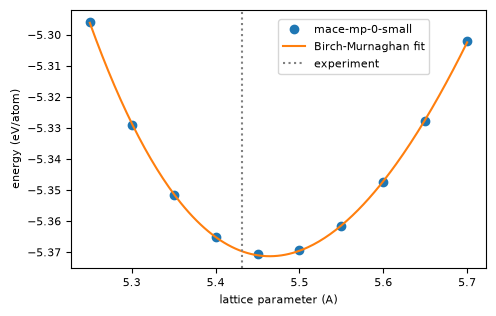

In [9]:
# Plot the energy vs lattice parameter and the fitted equation of state
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(lattice, np.array(energies) / 2, "o", label="mace-mp-0-small")
fine = np.linspace(volumes[0], volumes[-1], 200)
ax.plot((4 * fine) ** (1 / 3), eos.func(fine, *eos.eos_parameters) / 2, "-", label="Birch-Murnaghan fit")
ax.axvline(5.431, color="gray", ls=":", label="experiment")
ax.set_xlabel("lattice parameter (A)")
ax.set_ylabel("energy (eV/atom)")
ax.legend(loc=(.5, .75))
plt.tight_layout()

The lattice parameter lands on the PBE value, while the bulk modulus comes out
softer than tha of PBE: the curvature of the energy surface is underestimated,
the systematic softening known for universal potentials and most pronounced in
the small models. The larger pre-trained MACE models, `mace-mp-0-medium`, and
`mace-mpa-0-medium` can be loaded the same way.

## 5. Multi-head models

The `mace-mh-0` model carries seven heads, one per training set and level of
theory. A head is chosen at load time and each converted head gets its own
directory under `<cache>/mace-mh-0/heads/`. Without a head specified, the model
hub loader, `from_pretrained()`, stops before downloading anything and lists the
options instead:

In [10]:
try:
    from_pretrained("mace-mh-0", cache_dir=CACHE)
except ValueError as e:
    print("ValueError:", e)

ValueError: mace-mh-0 has 7 heads; pass head= with one of ['rgd1_b3lyp', 'matpes_r2scan', 'mp_pbe_refit_add', 'omol', 'spice_wB97M', 'oc20_usemppbe', 'omat_pbe']


Let's calculate the interaction energy of the same water dimer through three
heads, each trained on a different level of theory and dataset: two molecular
heads, involving wB97M-D3(BJ) on SPICE (`spice_wB97M`) and Omol (`omol`) as well
as the materials head using PBE (`omat_pbe`).

In [11]:
# Loop over the three heads of the `mace-mh-0` model 
for head in ("spice_wB97M", "omol", "omat_pbe"):
    
    # Create an ASE calculator from the pretrained model (`mace-mh-0`) with the
    # specified head
    calc_h = XNNCalculator.from_pretrained("mace-mh-0", head=head, cache_dir=CACHE)
    
    # Compute the interaction energy of the water dimer using the specified head
    parts = []
    for atoms in (dimer, dimer[:3], dimer[3:]):
        atoms = atoms.copy()
        atoms.calc = calc_h
        parts.append(atoms.get_potential_energy())
    e = parts[0] - parts[1] - parts[2]
    
    # Print the interaction energy computed by the specified head along with the
    # reference interaction energy from CCSD(T)/CBS calculations
    print(f"{head:12s} {e:8.4f} eV ({e * 23.0605:6.2f} kcal/mol)   [{calc_h.dtype}]")
print(f"{'CCSD(T)/CBS':12s} {ref:8.4f} eV ({ref * 23.0605:6.2f} kcal/mol)")

# Print the directory tree of the cached `mace-mh-0` model
# with the converted heads in their own subdirectories
tree(CACHE / "mace-mh-0")

spice_wB97M   -0.2172 eV ( -5.01 kcal/mol)   [torch.float32]
omol          -0.2152 eV ( -4.96 kcal/mol)   [torch.float32]
omat_pbe      -0.2284 eV ( -5.27 kcal/mol)   [torch.float32]
CCSD(T)/CBS   -0.2177 eV ( -5.02 kcal/mol)
heads/
    omat_pbe/
        card.json  (0.00 MB)
        config.yaml  (0.00 MB)
        model.pt  (39.63 MB)
    omol/
        card.json  (0.00 MB)
        config.yaml  (0.00 MB)
        model.pt  (39.63 MB)
    spice_wB97M/
        card.json  (0.00 MB)
        config.yaml  (0.00 MB)
        model.pt  (39.63 MB)


The molecular heads land within 0.1 kcal/mol of the coupled-cluster value. The
PBE head overbinds a little, as PBE itself does for hydrogen bonds. The
checkpoint stores float32 weights. As a result, these heads will also serve in
float32 unless `dtype=torch.float64` is passed. 

## 6. A `xnn` model trained on the liquid argon dataset

The `xnn-mace-argon` is the MACE model trained on the `argon_md` dataset
(400-atom periodic frames). Its registry entry has no DOI yet. So, it loads only
where it is cached (this repository's default cache holds the packed copy).
Requesting this model in a cache address that does not have it gives an explicit
error rather than a download attempt.

In [12]:
try:
    from_pretrained("xnn-mace-argon", cache_dir=CACHE)
except FileNotFoundError as e:
    print("FileNotFoundError:", e)

# Load the `xnn-mace-argon` model from the default cache
argon = load_pretrained("xnn-mace-argon")

# Print the path and description of the loaded model, along with its training
# configuration
print(f"\nloaded from {argon.path} | {argon.card.description}")
print(f"trained on {argon.config.data.batch_size}-frame batches, lr {argon.config.optim.lr}, "
      f"{argon.config.optim.epochs} epochs")

FileNotFoundError: xnn-mace-argon is registered but has no download source yet (its card names no DOI or URL) and is not cached in runs/model_cache

loaded from /D3/sina/xnns/models/xnn-mace-argon | MACE (2 layers, 32 channels, 6 A cutoff) trained on the argon_md liquid-argon set; the model of the MDI deployment examples
trained on 10-frame batches, lr 0.01, 30 epochs


The `load_pretrained()` returns the model together with its config file, model
card and cutoff radius. The configuration file shows how the model was trained.
In this case, the model was trained with the forces weighted 100 times more than
energies, the usual choice for a model meant for molecular dynamics. Then, the
model is scored on the held-out test frames of `argon_md`:

In [13]:
from xnn.common.data import load_dataset, structure_to_graph

# Evaluate the `xnn-mace-argon` model on the test split of the `argon_md`
# dataset
test = load_dataset("argon_md", split="test")

# Loop over the test dataset, compute the predicted energies and forces
de, f_ref, f_pred = [], [], []
for s in test:
    g = structure_to_graph(s, argon.cutoff)
    out = argon.model(g)
    de.append((float(out["energy"]) - s["energy"]) / len(s["atomic_numbers"]))
    f_ref.append(np.asarray(s["forces"]))
    f_pred.append(out["forces"].detach().numpy())
f_ref, f_pred = np.concatenate(f_ref), np.concatenate(f_pred)

# Print the loss weights and the mean absolute error (MAE) of the energy and
# force predictions
print(f"loss weights: energy {argon.config.optim.energy_weight}, forces {argon.config.optim.force_weight}")
print(f"{len(test)} frames | energy MAE {np.abs(de).mean() * 1e3:.2f} meV/atom "
      f"(mean signed {np.mean(de) * 1e3:+.1f}) | force MAE {np.abs(f_pred - f_ref).mean() * 1e3:.1f} meV/A")

loss weights: energy 1.0, forces 100.0
50 frames | energy MAE 13.41 meV/atom (mean signed -9.7) | force MAE 1.6 meV/A


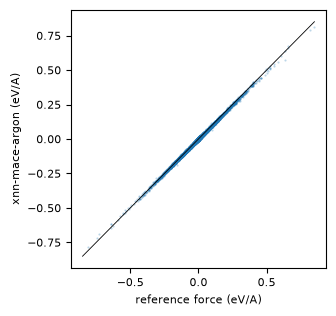

In [14]:
fig, ax = plt.subplots(figsize=(3.4, 3.2))
ax.plot(f_ref.ravel(), f_pred.ravel(), ".", ms=1, alpha=0.3)
lim = np.abs(f_ref).max()
ax.plot([-lim, lim], [-lim, lim], "k-", lw=0.6)
ax.set_xlabel("reference force (eV/A)")
ax.set_ylabel("xnn-mace-argon (eV/A)")
plt.tight_layout()

The forces, which drive the dynamics, are accurate to a few meV/A. However, the
absolute per-atom energies scatter by about 15 meV/atom, which is the cost of
using a force-heavy loss. The model card's `notes` field describes this aspect
users know what they are getting, for example when they use `list_models()` to
inspect the registry. 

## 7. Models published on Zenodo

Any Zenodo DOI or record link can work as a model source. For example:

- `doi:10.5281/zenodo.N`,
- `https://doi.org/10.5281/zenodo.N`,
- `https://zenodo.org/records/N`, or a
- `.../records/N/files/<file>` link 

that picks the file. The metadata for each record comes from Zenodo's API, which
also supplies the MD5 of every file which fills the model card's pertinent
description, license and citation fields. 

Record [10.5281/zenodo.18957344](https://doi.org/10.5281/zenodo.18957344)
(Laakso, Tiihonen and Rinke, CC-BY-4.0) holds two MACE models for
(Cs/FA)B(Cl/Br/I)3 hybrid perovskite alloys together with their DFT training and
test sets. A record with several model files needs `filename=`:

In [15]:
# Set the Zenodo DOI
DOI = "doi:10.5281/zenodo.18957344"

# Try to fetch the model using the specified DOI and cache directory.
try:
    fetch_model(DOI, cache_dir=CACHE)
except ValueError as e:
    print("ValueError:", e)

ValueError: Zenodo record 18957344 holds several model files; pass filename= with one of ['mace_csfapbbri_al_5_1_stagetwo.model', 'mace_csfasnbri_al_5_0_stagetwo.model']


In [16]:
# Load the model using the DOI and the specified filename, and print its card
pero = load_pretrained(DOI, filename="mace_csfapbbri_al_5_1_stagetwo.model", cache_dir=CACHE)

# Print the model's name, license, citation, cutoff radius, elements, and data
# type
print(f"name     {pero.card.name}\nlicense  {pero.card.license}\ncitation {pero.card.citation}")
print(f"cutoff   {pero.cutoff} A | elements {pero.card.species} | {pero.card.dtype}")

# Print the directory tree of the cached Zenodo model
tree(CACHE / "zenodo.18957344")

mace_csfapbbri_al_5_1_stagetwo.model:   0%|          | 0.00/3.46M [00:00<?, ?B/s]

name     zenodo.18957344/mace_csfapbbri_al_5_1_stagetwo.model
license  cc-by-4.0
citation Laakso, Jarno et al. (2026). (Cs/FA)B(Cl/Br/I)3 Hybrid Perovskite Alloy DFT Datasets and MACE Models. Zenodo. https://doi.org/10.5281/zenodo.18957344
cutoff   5.0 A | elements [1, 6, 7, 35, 53, 55, 82] | float32
mace_csfapbbri_al_5_1_stagetwo.model/
    card.json  (0.00 MB)
    config.yaml  (0.00 MB)
    model.pt  (3.40 MB)
record.json  (0.01 MB)


This Zenodo record ships the DFT test set for the model. Therefore, we can check
that the conversion reproduces the published accuracy. Note that this Zenodo
record and its files do not belong to xnn. However, they can come through the
same cached and MD5-verified downloader framework of the xnn's dataset hub.

In [17]:
from ase.io import read

from xnn.common.data.hub._download import download_file
from xnn.common.models.hub import zenodo

# Load the Zenodo record for the `csfapbbri_test.xyz` file
record = json.loads((CACHE / "zenodo.18957344" / "record.json").read_text())
entry = next(f for f in zenodo.files(record) if f["key"] == "csfapbbri_test.xyz")

# Download the `csfapbbri_test.xyz` file from Zenodo and cache it in the
# specified directory
xyz = download_file(entry["url"], CACHE / "perovskite_data" / entry["key"], md5=entry["md5"])

# Read the frames from the downloaded XYZ file
frames = read(xyz, ":")

# Create an ASE calculator from the pretrained model
# (`mace_csfapbbri_al_5_1_stagetwo.model`)
calc_p = XNNCalculator.from_pretrained("zenodo.18957344/mace_csfapbbri_al_5_1_stagetwo.model",
                                       cache_dir=CACHE, local_files_only=True)

# Loop over the frames, compute the predicted energies and forces, and store the
# differences between the predicted and reference values
de, f_ref, f_pred = [], [], []
for atoms in frames:
    e_dft, f_dft = atoms.get_potential_energy(), atoms.get_forces()
    atoms.calc = calc_p
    de.append((atoms.get_potential_energy() - e_dft) / len(atoms))
    f_ref.append(f_dft)
    f_pred.append(atoms.get_forces())
f_ref, f_pred = np.concatenate(f_ref), np.concatenate(f_pred)

# Print the number of frames, the range of atoms per frame, and the mean
# absolute error (MAE) of the energy and force predictions
print(f"{len(frames)} DFT test frames ({min(map(len, frames))}-{max(map(len, frames))} atoms) | "
      f"energy MAE {np.abs(de).mean() * 1e3:.2f} meV/atom | "
      f"force MAE {np.abs(f_pred - f_ref).mean() * 1e3:.1f} meV/A")

csfapbbri_test.xyz:   0%|          | 0.00/1.44M [00:00<?, ?B/s]

200 DFT test frames (40-96 atoms) | energy MAE 0.40 meV/atom | force MAE 10.5 meV/A


The cached model can now respond to both using its record link and to its cache
key in offline mode:

In [18]:
link = "https://zenodo.org/records/18957344/files/mace_csfapbbri_al_5_1_stagetwo.model"

print(fetch_model(link, cache_dir=CACHE, local_files_only=True))
print(fetch_model("zenodo.18957344/mace_csfapbbri_al_5_1_stagetwo.model", cache_dir=CACHE,
                  local_files_only=True))

runs/model_cache/zenodo.18957344/mace_csfapbbri_al_5_1_stagetwo.model
runs/model_cache/zenodo.18957344/mace_csfapbbri_al_5_1_stagetwo.model


## 8. Portability: sharing a cache directory

A model directory holds everything needed to rebuild the model and nothing tied
to the machine that wrote it. You can copy the cache directory anywhere, point
`cache_dir` (or `XNN_MODELS` environment variable) at the new location, and use
it as usual by calling the xnn model hub functions. Here a second directory can
exist in another machine. In this case, the MD5 checksum in the card confirms
that the copy remains intact.

In [19]:
import hashlib

# Copy the cached model to a different directory to simulate using it on another
# machine. 
elsewhere = Path("runs/other_machine/models")
shutil.rmtree(elsewhere.parent, ignore_errors=True)
shutil.copytree(CACHE / "mace-off23-small", elsewhere / "mace-off23-small")
shutil.copytree(CACHE / "zenodo.18957344", elsewhere / "zenodo.18957344")

# Check the MD5 checksums of the copied files against the original model card
card = model_card("mace-off23-small")
copied = json.loads((elsewhere / "mace-off23-small" / "card.json").read_text())
for name, md5 in copied["files"].items():
    ok = hashlib.md5((elsewhere / "mace-off23-small" / name).read_bytes()).hexdigest() == md5
    print(f"{name:12s} md5 {'ok' if ok else 'MISMATCH'}")

# Load the model from the copied cache directory and compare its energy predictions
moved = from_pretrained("mace-off23-small", cache_dir=elsewhere, local_files_only=True)
probe = structure_to_graph({"pos": dimer.positions, "atomic_numbers": dimer.numbers}, moved.cutoff)
probe.pos = probe.pos.double()
print("same energies:", float(moved(probe)["energy"]) == float(model(probe)["energy"]))
print("ready there:  ", [r["name"] for r in list_models(elsewhere, details=True)
                         if r["cached"] == "ready"])

config.yaml  md5 ok
model.pt     md5 ok
same energies: True
ready there:   ['mace-off23-small', 'zenodo.18957344/mace_csfapbbri_al_5_1_stagetwo.model']


The xnn environment variables allow you to set the defaults for the model cache
and offline mode. The `XNN_MODELS` variable sets the cache directory
(`XNN_CACHE/models` if only the `XNN_CACHE` variable is set. Otherwise, the
repository's `models/` directory in a source checkout is selected and
`~/.cache/xnn/models` in an installed package). Setting the `XNN_OFFLINE=1`
variable forbids network access everywhere system-wide, so that the model hub
functions will only load models that are already cached.

## 9. Sharing your own models

The `save_pretrained()` writes the model artifacts as a portable directory.
After training, you can use the one-liner function,
`trainer.save_pretrained("my-model", description=..., license=...)` to save the
artifacts. In order to share an existing checkpoint (e.g., a `best.pt` file),
use:

In [20]:
# Save the `xnn-mace-argon` model to a portable directory with a description,
# license, citation, and tags
packed = save_pretrained("../deploy/runs/mdi_argon/best.pt", CACHE / "my-argon",
                         description="MACE for liquid argon (my lab)", license="MIT",
                         citation="Me et al. (2026)", tags=["argon"])

# Print the directory tree of the saved model
tree(packed)

# Print the description of the saved model from its model card
print(model_card("my-argon", CACHE).description)

card.json  (0.00 MB)
config.yaml  (0.00 MB)
model.pt  (3.62 MB)
MACE for liquid argon (my lab)


The `xnn models` command performs the same task from a shell. Using the
`--archive` flag adds a `.zip` format of the cached directory:

```bash
xnn models pack runs/exp/best.pt my-model --description "..." --license MIT --archive
```

In order to publish your packaged model directory, upload its three files (or
the zip) to Zenodo. `from_pretrained("doi:10.5281/zenodo.<id>")` then works for
everyone, and an entry with that `doi` in
`src/xnn/common/models/hub/models.json` (or a `register_pretrained` call) gives
it a short name. Below, we use a `file://` URL for the upload, to demonstrate
the workflow: register, download, unpack, cache, load.

In [21]:
import subprocess
import sys

# Use the `xnn models pack` command to package the `best.pt` model into a
# portable directory with a description, license, and archive it as a zip file
run = subprocess.run([sys.executable, "-m", "xnn.common.cli.main", "models", "pack",
                      "../deploy/runs/mdi_argon/best.pt", "runs/upload/lab-argon",
                      "--description", "MACE for liquid argon", "--license", "MIT",
                      "--archive"], capture_output=True, text=True)

# Print the output of the `xnn models pack` command
print(run.stdout.strip())

# Register the packaged model with a name, URL, description, license, and
# architecture 
register_pretrained(name="lab-argon", url=Path("runs/upload/lab-argon.zip").resolve().as_uri(),
                    description="MACE for liquid argon", license="MIT", architecture="mace")

# Load the `lab-argon` model from the registered URL and cache directory
lab = load_pretrained("lab-argon", cache_dir=CACHE, quiet=True)

# Print the name of the loaded model, its path, and the source of the model card
print("loaded", lab.card.name, "from", lab.path, "| source:", lab.card.source.split("/")[-1])

wrote runs/upload/lab-argon
wrote /D3/sina/xnns/notebooks/examples/common/models/runs/upload/lab-argon.zip
loaded lab-argon from runs/model_cache/lab-argon | source: lab-argon.zip


## 10. Consistent namings across all xnn interfaces

Everything that loads a model goes through the model hub. As such, a registered
name, a DOI or a cache key works like a checkpoint path. Here are some examples
of where the same model name can be used:

* In the Python API:
  - `XNNCalculator.from_pretrained(...)` (above), and 
  - `Model.from_pretrained(...)` for the bare potential of a given class,
* MDI engine:
  - Python API: `MDIEngine.from_checkpoint(...)`, and 
  - CLI: `xnn mdi --ckpt mace-off23-small ...`,
* Torchscript and LAMMPS:
  - CLI: `xnn export --ckpt mace-off23-small --to lammps`,
* a benchmark YAML entry:
  - `checkpoint: mace-off23-small`,
* Foundation model loader:
  - Python API: `MACE.from_foundation("mace-off23-small")`, and 
  - YAML config file entry: `model: {name: mace, foundation: mace-off23-small}`.

In [22]:
from xnn.common.deploy import MDIEngine
from xnn.gnn.models.mace import MACE

# Load the `mace-off23-small` model using the MDIEngine
engine = MDIEngine.from_checkpoint("mace-off23-small", cache_dir=CACHE)
print("MDI engine:      cutoff", engine.cutoff, "|", engine.dtype)

# Load the `mace-off23-small` model using the MACE class from both the
# pretrained and foundation methods
bare = MACE.from_pretrained("mace-off23-small", cache_dir=CACHE)
via_foundation = MACE.from_foundation("mace-off23-small", cache_dir=CACHE)
print("MACE classes:   ", type(bare).__name__, type(via_foundation).__name__)

# List the available models in the cache directory using the `xnn models list` command
run = subprocess.run([sys.executable, "-m", "xnn.common.cli.main", "models", "list", "--cached",
                      "--format", "xnn", "--cache-dir", str(CACHE)], capture_output=True, text=True)

# Print the output of the `xnn models list` command
print(run.stdout)

MDI engine:      cutoff 4.5 | torch.float64
MACE classes:    MACE MACE
name                                                  architecture  format  cutoff  elements  heads  license    cached  description                                                            
----------------------------------------------------  ------------  ------  ------  --------  -----  ---------  ------  -----------------------------------------------------------------------
lab-argon                                             mace          xnn     6       1                MIT        ready   MACE for liquid argon                                                  
my-argon                                              mace          xnn     6       1                MIT        ready   MACE for liquid argon (my lab)                                         
zenodo.18957344/mace_csfapbbri_al_5_1_stagetwo.model  mace          xnn     5       7                cc-by-4.0  ready   (Cs/FA)B(Cl/Br/I)3 Hybrid Perovskite Allo

## Summary

Let's summarize the main tasks and their corresponding function calls and CLI
commands we have seen in this notebook:

| task | call |
|---|---|
| list models | API: `list_models()`, `list_models(details=True)`; CLI: `xnn models list` |
| inspect a model | API: `model_card(name)`; CLI: `xnn models info NAME` |
| load a model | `from_pretrained(source)`, `load_pretrained(source)` (with config, card, cutoff) |
| model sources | registry name, local directory or `best.pt`, URL, Zenodo DOI or record link, cache key |
| options of model hub function calls | `cache_dir`, `head`, `filename`, `dtype`, `device`, `dispersion`, `compute_stress`, `local_files_only`, `force_download` |
| ASE calculator | `XNNCalculator.from_pretrained(source)` |
| download-only functions | API: `fetch_model(source)`; CLI: `xnn models pull SOURCE` |
| share a model | API: `save_pretrained(model_or_ckpt, dir)`, `Trainer.save_pretrained(dir)`; CLI: `xnn models pack` |
| register a model | `register_pretrained(name=..., doi=...)`, or an entry in `models.json` |

Note that the MACE foundation models, xnn-trained models and third-party uploads
share one registry, one cache layout and one load interface. A converted model
is stored in the portable xnn format. Thus, after the first model load, xnn will
not need the network connection or the upstream package to load the model again. 